In [6]:
import os
import cv2
import numpy as np
from collections import Counter

DATA_DIR = "data/Data"

def count_extensions(folder):
    files = os.listdir(folder)
    return Counter(os.path.splitext(f)[1].lower() for f in files)

print(os.getcwd())
print(sorted(os.listdir(DATA_DIR)))

/
['glioma', 'meningioma', 'notumor', 'pituitary']


In [7]:
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]

for class_name in CLASSES:
    folder = os.path.join(DATA_DIR, class_name)
    print(class_name, sum(count_extensions(folder).values()), count_extensions(folder))

glioma 1621 Counter({'.jpg': 1621})
meningioma 1645 Counter({'.jpg': 1645})
notumor 2000 Counter({'.jpg': 2000})
pituitary 1757 Counter({'.jpg': 1757})


In [8]:
VALID_EXT = {".jpeg", ".jpg", ".bmp", ".png"}
IMG_SIZE = 224

def scan_dataset(data_dir, classes, valid_ext):
    kept, rejected = [], []
    for label in classes:
        folder = os.path.join(data_dir, label)
        for filename in os.listdir(folder):
            path = os.path.join(folder, filename)
            if os.path.splitext(filename)[1].lower() not in valid_ext:
                rejected.append((path, "bad extension"))
                continue
            try:
                img = cv2.imread(path)
                if img is None:                      
                    rejected.append((path, "unreadable"))
                else:
                    kept.append((path, label))
            except Exception as e:
                rejected.append((path, str(e)))
    return kept, rejected

def load_image(path, size=IMG_SIZE):
    img = cv2.imread(path)
    if img is None:
        raise ValueError(f"Unreadable image: {path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)       
    return cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)

kept, rejected = scan_dataset(DATA_DIR, CLASSES, VALID_EXT)
print(len(kept), len(rejected), len(kept) + len(rejected))   

[ WARN:0@118485.631] global loadsave.cpp:278 findDecoder imread_('data/Data/notumor/Te-no_0240.jpg'): can't open/read file: check file path/integrity
[ WARN:0@118485.682] global loadsave.cpp:278 findDecoder imread_('data/Data/notumor/Te-no_0241.jpg'): can't open/read file: check file path/integrity
[ WARN:0@118485.709] global loadsave.cpp:278 findDecoder imread_('data/Data/notumor/Te-no_0242.jpg'): can't open/read file: check file path/integrity
[ WARN:0@118485.709] global loadsave.cpp:278 findDecoder imread_('data/Data/notumor/Te-no_0243.jpg'): can't open/read file: check file path/integrity
[ WARN:0@118485.709] global loadsave.cpp:278 findDecoder imread_('data/Data/notumor/Te-no_0244.jpg'): can't open/read file: check file path/integrity
[ WARN:0@118485.709] global loadsave.cpp:278 findDecoder imread_('data/Data/notumor/Te-no_0245.jpg'): can't open/read file: check file path/integrity
[ WARN:0@118485.709] global loadsave.cpp:278 findDecoder imread_('data/Data/notumor/Te-no_0246.jpg')

FileNotFoundError: [Errno 2] No such file or directory: 'data/Data/pituitary'

2026-10-28 00:57:43.159974: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793149063.179090    1467 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793149063.184666    1467 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793149063.198958    1467 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793149063.198971    1467 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793149063.198973    1467 computation_placer.cc:177] computation placer alr

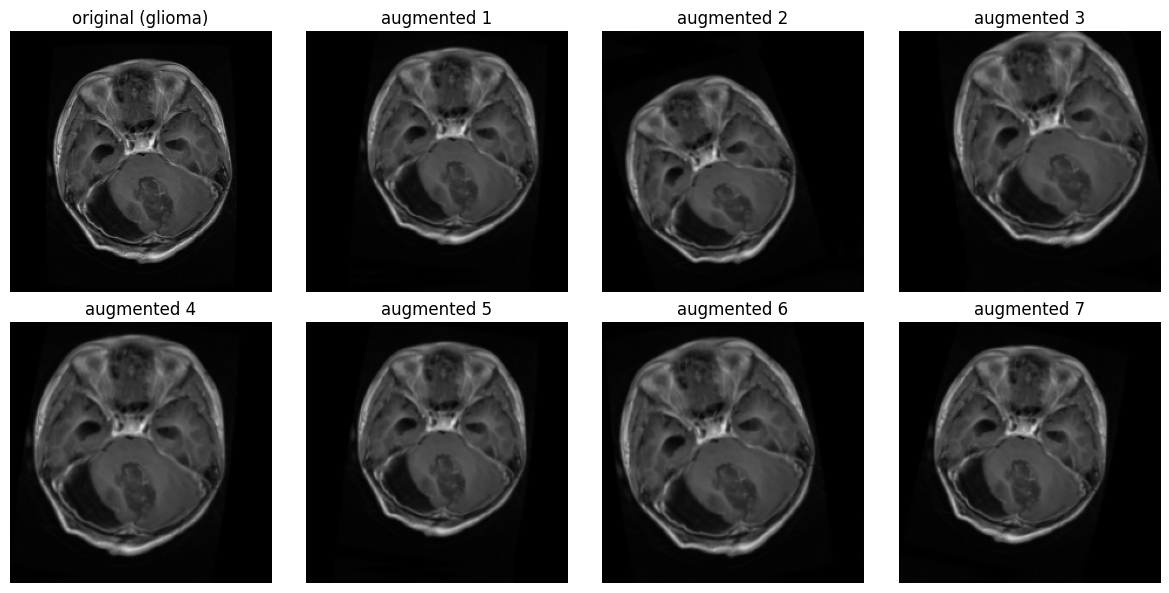

In [ ]:
import matplotlib.pyplot as plt
import keras
from keras import layers

augment = keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
])

path, label = kept[0]
img = load_image(path)[None].astype("float32")   

plt.figure(figsize=(12, 6))
plt.subplot(2, 4, 1)
plt.imshow(img[0].astype("uint8")); plt.title(f"original ({label})"); plt.axis("off")

for i in range(7):
    out = augment(img, training=True)              
    plt.subplot(2, 4, i + 2)
    plt.imshow(np.array(out[0]).astype("uint8"))
    plt.title(f"augmented {i + 1}"); plt.axis("off")

plt.tight_layout()
plt.show()